# 07 — Retrieve regridded fields from the REF API

**Goal:** discover saved gridded data, download NetCDF files, and reuse them with xarray.
**Prerequisites:** notebooks 01–02 and the repository environment, including the generated API client.
Run `uv sync`, `uv run bash scripts/generate_client.sh`, then `uv run jupyter lab notebooks`
from the repository root. An internet connection is required. No REF API key is needed for these public results.

**Yes, with a qualification:** the API exposes regridded fields **when a diagnostic has saved
and published them as outputs**. It does not provide a general archive of all intermediate
preprocessor files, or an on-demand regridding service.

This example retrieves **ACCESS-ESM1-6 / historical / r1i1p1f1** precipitation and its
**GPCP** reference from **ESMValTool → ENSO Basic Climatology**. These are ocean-masked,
time-mean fields on a **1° × 1° grid**, over **150–270°E, 15°S–15°N**. They are not full
global monthly time series. The model and reference averaging periods must be inspected
before any comparison.

Verified against the live service on **11 November 2026**. The saved outputs below make
this notebook readable without rerunning it; future runs query the live API again.

## 1. Choose the diagnostic and simulation

We use the same generated client and execution-selection helper as the earlier notebooks.
Change the model, experiment or member here to explore another run of this diagnostic.
Changing the diagnostic also requires reviewing its file names and processing assumptions.

In [1]:
import hashlib
import json
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import pandas as pd
import requests
import xarray as xr
from climate_ref_client.api.diagnostics import diagnostics_list_execution_groups
from climate_ref_client.api.executions import executions_get
from IPython.display import display

from ref_tutorials import get_client, latest_successful_execution

client = get_client().with_timeout(120.0)
PROVIDER = "esmvaltool"
DIAGNOSTIC = "enso-basic-climatology"
MIP_ERA = "CMIP7"
MODEL = "ACCESS-ESM1-6"
EXPERIMENT = "historical"
MEMBER = "r1i1p1f1"
REFERENCE_FILE_LABEL = "GPCP-V3.3"
VARIABLE = "pr"

# Leave these as None to discover the current group and its latest successful run.
# To reproduce the checked example exactly, use GROUP_ID = 29823 and EXECUTION_ID = 86440.
GROUP_ID = None
EXECUTION_ID = None

## 2. Discover the group, then select a successful execution

An **execution group** identifies the diagnostic's input selection; an **execution** is
one run of that selection. The diagnostic endpoint returns its groups at the promoted
version (this endpoint has no pagination parameters in the current API).

We require an exact match and exclude retracted or unsuccessful executions. Pin both IDs
above if you need a specific run rather than the latest available result.

In [2]:
wanted = {"source_id": MODEL, "experiment_id": EXPERIMENT, "variant_label": MEMBER}
if GROUP_ID is None:
    response = diagnostics_list_execution_groups.sync(PROVIDER, DIAGNOSTIC, mip_era=MIP_ERA, client=client)
    if response is None or not hasattr(response, "data"):
        raise RuntimeError(f"Could not list REF execution groups: {response!r}")
    matches = [
        group
        for group in response.data
        if all(
            dict(group.selectors.to_dict().get(MIP_ERA.lower(), [])).get(key) == value
            for key, value in wanted.items()
        )
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one matching group; found {[g.id for g in matches]}")
    group_id = matches[0].id
else:
    group_id = GROUP_ID

# Fetch the group detail to obtain the full output inventory.
group = executions_get.sync(str(group_id), client=client)
if group is None or not hasattr(group, "executions"):
    raise RuntimeError(f"Could not read REF group {group_id}: {group!r}")
selectors = dict(group.selectors.to_dict().get(MIP_ERA.lower(), []))
if (group.provider_slug, group.diagnostic_slug) != (PROVIDER, DIAGNOSTIC):
    raise ValueError("The pinned group belongs to a different diagnostic")
if not all(selectors.get(key) == value for key, value in wanted.items()):
    raise ValueError(f"The pinned group has different selectors: {selectors}")

if EXECUTION_ID is None:
    execution = latest_successful_execution(group)
else:
    execution = next((run for run in group.executions if run.id == EXECUTION_ID), None)
if execution is None or not execution.successful or execution.retracted:
    raise ValueError("No matching successful, non-retracted execution is available")

print(f"Group {group.id}; execution {execution.id}; created {execution.created_at}")
print(selectors)
print(f"https://dashboard.climate-ref.org/executions/{group.id}/files")

Group 29823; execution 86440; created 2026-10-24 23:09:36
{'experiment_id': 'historical', 'source_id': 'ACCESS-ESM1-6', 'variant_label': 'r1i1p1f1'}
https://dashboard.climate-ref.org/executions/29823/files


## 3. List the downloadable NetCDF outputs

Each output has a URL supplied by the API. Follow that URL instead of constructing a
storage path. Other diagnostics may publish only plots, or different derived variables.
A `.nc` extension alone does not establish that a file contains a full regridded field.

In [3]:
netcdfs = [
    item
    for item in (execution.outputs or [])
    if item.output_type.value == "data" and item.filename.lower().endswith(".nc")
]
if not netcdfs:
    raise ValueError("This execution publishes no NetCDF data outputs")

inventory = pd.DataFrame(
    [{"result_id": item.id, "filename": Path(item.filename).name, "url": item.url} for item in netcdfs]
)
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 40):
    display(inventory)

,result_id,filename,url
0,2232554,ACCESS-ESM1-6_pr_map_bias_level2.nc,https://api.climate-ref.org/api/v1/results/2232554
1,2232555,ACCESS-ESM1-6_pr_map_sea_cyclel2.nc,https://api.climate-ref.org/api/v1/results/2232555
2,2232556,ACCESS-ESM1-6_tauu_map_bias_level2.nc,https://api.climate-ref.org/api/v1/results/2232556
3,2232557,ACCESS-ESM1-6_tos_map_bias_level2_sea.nc,https://api.climate-ref.org/api/v1/results/2232557
4,2232558,GPCP-V3.3_pr_map_bias_level2.nc,https://api.climate-ref.org/api/v1/results/2232558
5,2232559,GPCP-V3.3_pr_map_sea_cyclel2.nc,https://api.climate-ref.org/api/v1/results/2232559
6,2232560,TROPFLUX_tauu_map_bias_level2.nc,https://api.climate-ref.org/api/v1/results/2232560
7,2232561,TROPFLUX_tos_map_bias_level2_sea.nc,https://api.climate-ref.org/api/v1/results/2232561
8,2232562,ACCESS-ESM1-6_pr_doubleITCZ_seacycle_level3.nc,https://api.climate-ref.org/api/v1/results/2232562
9,2232563,ACCESS-ESM1-6_pr_pr_seacycle_level3.nc,https://api.climate-ref.org/api/v1/results/2232563


Select the model and reference **time-mean precipitation fields** explicitly. Although
`bias` appears in the filename and caption, each file contains one dataset's precipitation,
not an already-subtracted model-minus-observation field. The diagnostic's
[plotting code](https://github.com/ESMValGroup/ESMValTool/blob/v2.15.0/esmvaltool/diag_scripts/enso_metrics/climatology_diagnosticlevel2.py)
saves the model and reference separately.

In [4]:
filenames = {
    "model": f"{MODEL}_{VARIABLE}_map_bias_level2.nc",
    "reference": f"{REFERENCE_FILE_LABEL}_{VARIABLE}_map_bias_level2.nc",
}
selected = {}
for role, filename in filenames.items():
    matches = [item for item in netcdfs if Path(item.filename).name == filename]
    if len(matches) != 1:
        raise ValueError(f"Expected one {filename}; found {len(matches)}. Inspect the inventory above.")
    selected[role] = matches[0]
    print(role, selected[role].url)

model https://api.climate-ref.org/api/v1/results/2232554
reference https://api.climate-ref.org/api/v1/results/2232558


## 4. Download the files and record their provenance

Downloads are streamed to disk, checked for HTTP errors, and capped at 20 MiB per file.
The checked example is about 40 kB per file. Files and a provenance manifest stay under
`data/ref-regridded/`, in a directory specific to this group and execution. A partial download
does not replace a completed file.

In [5]:
download_dir = Path("data/ref-regridded") / f"group-{group.id}" / f"execution-{execution.id}"
download_dir.mkdir(parents=True, exist_ok=True)
paths = {}
file_records = []
max_bytes = 20 * 1024 * 1024

with requests.Session() as session:
    for role, item in selected.items():
        destination = download_dir / f"{item.id}-{Path(item.filename).name}"
        partial = destination.with_suffix(".nc.part")
        digest = hashlib.sha256()
        size = 0
        try:
            with session.get(item.url, stream=True, timeout=(10, 120)) as response:
                response.raise_for_status()
                with partial.open("wb") as stream:
                    for chunk in response.iter_content(64 * 1024):
                        size += len(chunk)
                        if size > max_bytes:
                            raise ValueError("Download exceeded the 20 MiB example limit")
                        stream.write(chunk)
                        digest.update(chunk)
            partial.replace(destination)
        finally:
            partial.unlink(missing_ok=True)
        paths[role] = destination
        file_records.append(
            {
                "role": role,
                "result_id": item.id,
                "filename": item.filename,
                "url": item.url,
                "local_filename": destination.name,
                "bytes": size,
                "sha256": digest.hexdigest(),
            }
        )
        print(f"{role}: {size:,} bytes -> {destination.name}")

manifest = {
    "retrieved_at_utc": datetime.now(UTC).isoformat(),
    "api_url": "https://api.climate-ref.org",
    "provider": PROVIDER,
    "diagnostic": DIAGNOSTIC,
    "execution_group_id": group.id,
    "execution_id": execution.id,
    "execution_created_at": execution.created_at.isoformat(),
    "selectors": group.selectors.to_dict(),
    "files": file_records,
}
manifest_path = download_dir / "provenance.json"
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Provenance:", manifest_path)

model: 40,614 bytes -> 2232554-ACCESS-ESM1-6_pr_map_bias_level2.nc
reference: 37,279 bytes -> 2232558-GPCP-V3.3_pr_map_bias_level2.nc
Provenance: data/ref-regridded/group-29823/execution-86440/provenance.json


## 5. Open with xarray and inspect the actual grid and period

These files contain NetCDF's default missing-value sentinel without an explicit
`_FillValue` attribute. xarray does not mask that sentinel automatically in the checked
files. Mask the exact default value for the variable's numeric type, preserving the
unmodified downloads and their metadata.

Some global attributes describe the **original input**, including `grid_label`,
`nominal_resolution`, `frequency` and `region`. Inspect coordinates, dimensions,
`cell_methods` and time bounds to establish the **processed output** actually available.

In [6]:
datasets = {}
for role, path in paths.items():
    with xr.open_dataset(path, engine="netcdf4") as opened:
        dataset = opened.load()
    field = dataset[VARIABLE]
    fill_key = f"{field.dtype.kind}{field.dtype.itemsize}"
    default_fill = netCDF4.default_fillvals.get(fill_key)
    if default_fill is not None:
        missing = field == default_fill
        print(f"{role}: masking {int(missing.sum())} default NetCDF fill values")
        dataset[VARIABLE] = field.where(~missing)
    datasets[role] = dataset

# A compact view; the full global attributes remain in datasets["model"].attrs.
display(datasets["model"][[VARIABLE]])

/home/romain/PROJECTS/ACCESS-MOPPy/.pixi/envs/esmval/lib/python3.13/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


model: masking 6 default NetCDF fill values
reference: masking 4 default NetCDF fill values


<xarray.Dataset> Size: 16kB
Dimensions:  (lat: 30, lon: 120)
Coordinates:
  * lat      (lat) float64 240B -14.5 -13.5 -12.5 -11.5 ... 11.5 12.5 13.5 14.5
  * lon      (lon) float64 960B 150.5 151.5 152.5 153.5 ... 267.5 268.5 269.5
    time     datetime64[ns] 8B 1936-07-02T12:00:00
Data variables:
    pr       (lat, lon) float32 14kB 5.039 5.22 5.435 5.67 ... nan nan nan nan
Attributes: (12/50)
    Conventions:                    CF-1.7
    access_experiment_uuid:         01409bc3-2ad3-4d0e-9552-074979ac631d
    access_moppy_doi:               https://doi.org/10.5281/zenodo.21385771
    access_moppy_version:           1.8.1
    access_name:                    historical-historical-1.1-r1i1p1f1-01409bc3
    access_parent_experiment_uuid:  e523e199-80f6-4ca6-b84a-e513a16f2029
    ...                             ...
    temporal_label:                 tavg
    title:                          ACCESS-ESM1-6 output prepared for CMIP7
    variable_id:                    pr
    variant_label:                  r1i1p1f1
    vertical_label:                 u
    caption:                        Time-mean precipitation bias in the equat...

In [7]:
summary = []
for role, dataset in datasets.items():
    field = dataset[VARIABLE]
    if set(field.dims) != {"lat", "lon"}:
        raise ValueError(f"Expected a time-mean lat/lon field, got {field.dims}")
    if not np.isfinite(field).any():
        raise ValueError(f"No valid values in {role}")
    if not (np.allclose(np.diff(dataset.lat), 1.0) and np.allclose(np.diff(dataset.lon), 1.0)):
        raise ValueError("The current output is no longer on the expected 1-degree grid")
    bounds_name = dataset.time.attrs.get("bounds")
    if not bounds_name or bounds_name not in dataset:
        raise ValueError("Time bounds are missing; verify the averaging period before using this field")
    bounds = [str(value)[:10] for value in dataset[bounds_name].values.ravel()]
    summary.append(
        {
            "role": role,
            "source_id": dataset.attrs.get("source_id"),
            "shape": str(dict(field.sizes)),
            "units": field.attrs.get("units"),
            "period_start": bounds[0],
            "period_end_exclusive": bounds[-1],
            "lat_centres": f"{float(dataset.lat.min())} to {float(dataset.lat.max())}",
            "lon_centres": f"{float(dataset.lon.min())} to {float(dataset.lon.max())}",
            "cell_methods": field.attrs.get("cell_methods"),
        }
    )
summary = pd.DataFrame(summary).set_index("role")
display(summary.T)

model, reference = (datasets[role][VARIABLE] for role in ("model", "reference"))
# Exact coordinate matching prevents silent alignment onto a smaller common grid.
model, reference = xr.align(model, reference, join="exact")
if model.attrs.get("units") != reference.attrs.get("units"):
    raise ValueError("Convert the units before comparing these fields")
same_period = (
    summary.loc["model", ["period_start", "period_end_exclusive"]].tolist()
    == summary.loc["reference", ["period_start", "period_end_exclusive"]].tolist()
)
print("Same averaging period:", same_period)
if not same_period:
    print("Different averaging periods: these files cannot provide a matched-period bias.")

role,model,reference
source_id,ACCESS-ESM1-6,GPCP-3-3
shape,"{'lat': 30, 'lon': 120}","{'lat': 30, 'lon': 120}"
units,mm/day,mm/day
period_start,1850-01-01,1983-01-01
period_end_exclusive,2023-01-01,2022-01-01
lat_centres,-14.5 to 14.5,-14.5 to 14.5
lon_centres,150.5 to 269.5,150.5 to 269.5
cell_methods,area: time: mean time: mean,area: time: mean time: mean


Same averaging period: False
Different averaging periods: these files cannot provide a matched-period bias.


For the checked execution, the model spans **1850-01-01 to 2023-01-01 (exclusive)**,
whereas GPCP spans **1983-01-01 to 2022-01-01 (exclusive)**. The time dimension has already
been collapsed. Slicing this output cannot recover a common averaging period: that requires
rerunning the preprocessing with the desired years or obtaining a time-resolved product.

The [ESMValTool v2.15.0 recipe](https://github.com/ESMValGroup/ESMValTool/blob/v2.15.0/esmvaltool/recipes/ref/recipe_enso_basicclimatology_CMIP7.yml)
specifies the time mean, linear regridding to `1x1`, and regional extraction. The file's
`software` attribute identifies this ESMValTool version. The notebook shows the saved
climatologies individually and does not present their difference as a matched-period bias.

## 6. Make a new figure from the data

This figure is drawn locally from NetCDF values; it does not download a pre-rendered REF
plot. Both panels share a colour scale and identify their own averaging periods.

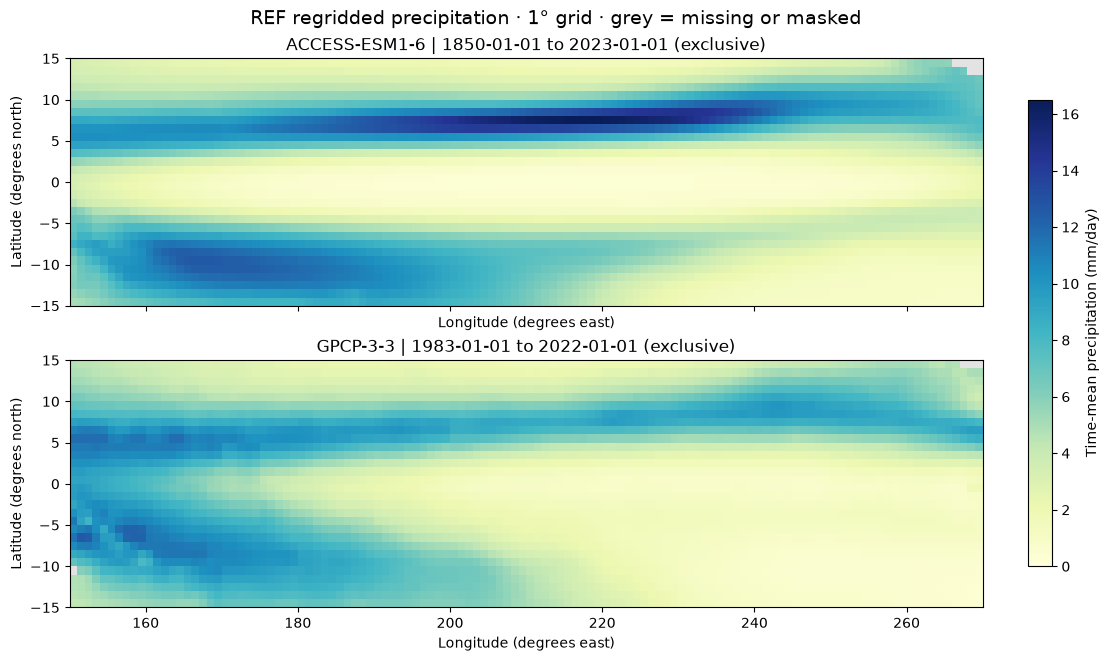

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, sharey=True, layout="constrained")
vmax = max(float(model.max()), float(reference.max()))
for ax, (role, field) in zip(axes, [("model", model), ("reference", reference)], strict=True):
    row = summary.loc[role]
    mesh = field.plot.pcolormesh(
        ax=ax, x="lon", y="lat", cmap="YlGnBu", vmin=0, vmax=vmax, add_colorbar=False
    )
    ax.set_facecolor("#e3e3e3")
    ax.set_title(f"{row['source_id']} | {row['period_start']} to {row['period_end_exclusive']} (exclusive)")
    ax.set(xlabel="Longitude (degrees east)", ylabel="Latitude (degrees north)")
fig.colorbar(mesh, ax=axes, label=f"Time-mean precipitation ({model.attrs['units']})", shrink=0.85)
fig.suptitle("REF regridded precipitation · 1° grid · grey = missing or masked", fontsize=14)
figure_path = download_dir / "regridded-precipitation.png"
fig.savefig(figure_path, dpi=150)
plt.show()
plt.close(fig)

## 7. Reuse a spatial subset

The downloaded data can be sliced and analysed like any xarray field. Longitudes in this
example use 0–360°. This selects the eastern equatorial Pacific without further regridding.
It remains a time mean over the model period printed above.

In [9]:
eastern_pacific = datasets["model"][[VARIABLE]].sel(lat=slice(-10, 10), lon=slice(210, 270))
print("Subset shape:", dict(eastern_pacific[VARIABLE].sizes))
print(
    "Precipitation range:",
    float(eastern_pacific[VARIABLE].min()),
    "to",
    float(eastern_pacific[VARIABLE].max()),
    model.attrs["units"],
)
print("Downloaded files and provenance are in:", download_dir.resolve())

Subset shape: {'lat': 20, 'lon': 60}
Precipitation range: 0.3202589452266693 to 16.506999969482422 mm/day
Downloaded files and provenance are in: /home/romain/Documents/ChatGPT/REF_announcement/climate-ref-tutorials/notebooks/data/ref-regridded/group-29823/execution-86440


## What this enables — and what would need a REF change

- **Available now:** discover published outputs through the API, download their NetCDF
  URLs, and reuse retained regridded climatologies or other diagnostic products.
- **Diagnostic-specific:** grids, domains, masks, variables and temporal reductions vary.
  A map of seasonal-cycle amplitude is not a monthly time series; inspect each product.
- **Not generally exposed:** all original preprocessor intermediates, arbitrary variables,
  user-selected target grids, or a guaranteed complete monthly regridded archive.
- **The archive is not a workaround for missing intermediates.**
  `GET /api/v1/executions/{group_id}/archive?execution_id={execution_id}` returns persisted
  results. The checked PMP Annual Cycle group **30985**, execution **91476**, contained
  five PNG plots, a log and three JSON files, and no NetCDF data. This observation applies
  to that execution, not every PMP execution.

REF's [output persistence code](https://github.com/Climate-REF/climate-ref/blob/0e3c5c9208f6fff8632ae1abeeb580b70cd6bbaf/packages/climate-ref-core/src/climate_ref_core/output_files.py)
copies a curated set of result files, rather than all scratch files. If Christine needs
complete regridded monthly fields, the relevant provider would need to save and register
those products (and retain the required temporal coverage). They could then use the same
API download pattern. Already discarded intermediates may require a rerun.

Keep the execution IDs, download URLs, file hashes, processing version, averaging periods
and original attribution/licence information with any reused data. The saved JSON manifest
records the retrieval; source metadata remain in the original NetCDF files.

Further reading: [REF API schema](https://api.climate-ref.org/api/v1/openapi.json),
[official pre-computed-results notebook](https://climate-ref.readthedocs.io/en/latest/how-to-guides/using-pre-computed-results/),
and [the checked execution](https://dashboard.climate-ref.org/executions/29823/files).